In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()
df = pd.read_csv("StudentsPerformance.csv")

print("Dataset loaded successfully!")

Saving StudentsPerformance.csv to StudentsPerformance.csv
Dataset loaded successfully!


In [7]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.info()

Number of rows: 1000
Number of columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [9]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [10]:
subject_columns = ["math score", "reading score", "writing score"]

negative_values = (df[subject_columns] < 0).sum()

print("Negative Marks:")
print(negative_values)

Negative Marks:
math score       0
reading score    0
writing score    0
dtype: int64


In [11]:
df[subject_columns].describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [12]:
subject_averages = df[subject_columns].mean()

print("Average Marks per Subject")
print("-" * 35)

for subject, average in subject_averages.items():
    print(f"{subject.title():<20}: {average:.2f}")

Average Marks per Subject
-----------------------------------
Math Score          : 66.09
Reading Score       : 69.17
Writing Score       : 68.05


In [13]:
average_table = pd.DataFrame({
    "Subject": ["Math", "Reading", "Writing"],
    "Average Marks": [
        df["math score"].mean(),
        df["reading score"].mean(),
        df["writing score"].mean()
    ]
})

average_table

,Subject,Average Marks
0,Math,66.089
1,Reading,69.169
2,Writing,68.054


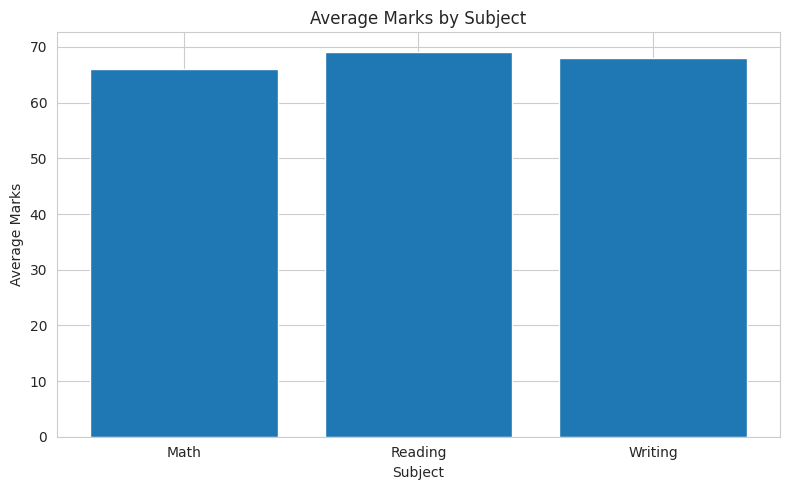

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    average_table["Subject"],
    average_table["Average Marks"]
)

plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")

plt.tight_layout()
plt.show()

In [15]:
df["Student ID"] = range(1, len(df) + 1)

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Student ID
0,female,group B,bachelor's degree,standard,none,72,72,74,1
1,female,group C,some college,standard,completed,69,90,88,2
2,female,group B,master's degree,standard,none,90,95,93,3
3,male,group A,associate's degree,free/reduced,none,47,57,44,4
4,male,group C,some college,standard,none,76,78,75,5


In [16]:
df["Total Marks"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
)

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Student ID,Total Marks
0,female,group B,bachelor's degree,standard,none,72,72,74,1,218
1,female,group C,some college,standard,completed,69,90,88,2,247
2,female,group B,master's degree,standard,none,90,95,93,3,278
3,male,group A,associate's degree,free/reduced,none,47,57,44,4,148
4,male,group C,some college,standard,none,76,78,75,5,229


In [17]:
df["Average Marks"] = df["Total Marks"] / 3

df[["Student ID", "Total Marks", "Average Marks"]].head()

,Student ID,Total Marks,Average Marks
0,1,218,72.666667
1,2,247,82.333333
2,3,278,92.666667
3,4,148,49.333333
4,5,229,76.333333


In [18]:
top_5_students = (
    df.sort_values("Total Marks", ascending=False)
      .head(5)
)

top_5_students[
    [
        "Student ID",
        "math score",
        "reading score",
        "writing score",
        "Total Marks",
        "Average Marks"
    ]
]

,Student ID,math score,reading score,writing score,Total Marks,Average Marks
916,917,100,100,100,300,100.000000
962,963,100,100,100,300,100.000000
458,459,100,100,100,300,100.000000
114,115,99,100,100,299,99.666667
712,713,98,100,99,297,99.000000


In [19]:
top_5_display = top_5_students[
    [
        "Student ID",
        "math score",
        "reading score",
        "writing score",
        "Total Marks",
        "Average Marks"
    ]
].copy()

top_5_display

,Student ID,math score,reading score,writing score,Total Marks,Average Marks
916,917,100,100,100,300,100.000000
962,963,100,100,100,300,100.000000
458,459,100,100,100,300,100.000000
114,115,99,100,100,299,99.666667
712,713,98,100,99,297,99.000000


# Top 5 Students Bar Char

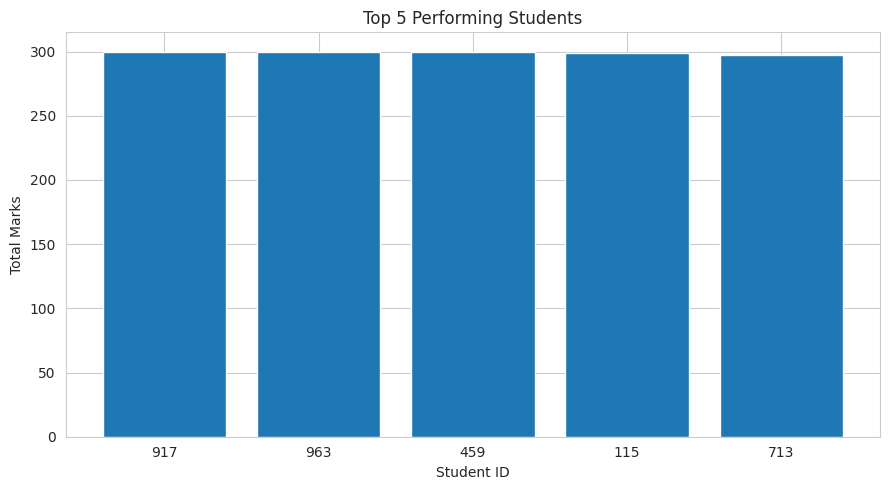

In [20]:
plt.figure(figsize=(9, 5))

plt.bar(
    top_5_display["Student ID"].astype(str),
    top_5_display["Total Marks"]
)

plt.title("Top 5 Performing Students")
plt.xlabel("Student ID")
plt.ylabel("Total Marks")

plt.tight_layout()
plt.show()

# Math Score Distribution

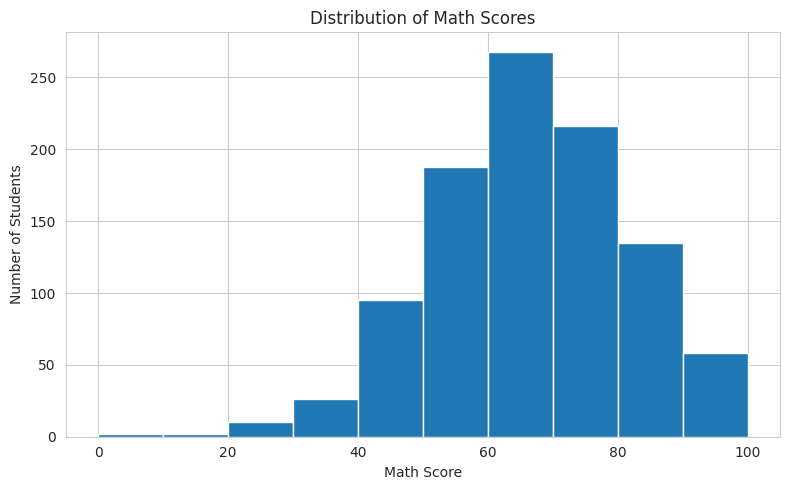

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(df["math score"], bins=10)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

# Reading Score Distribution

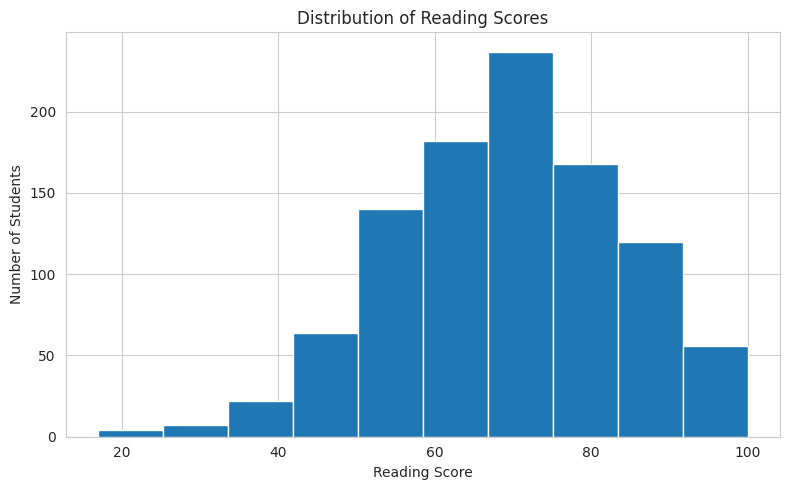

In [22]:
plt.figure(figsize=(8, 5))

plt.hist(df["reading score"], bins=10)

plt.title("Distribution of Reading Scores")
plt.xlabel("Reading Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

# Writing Score Distribution

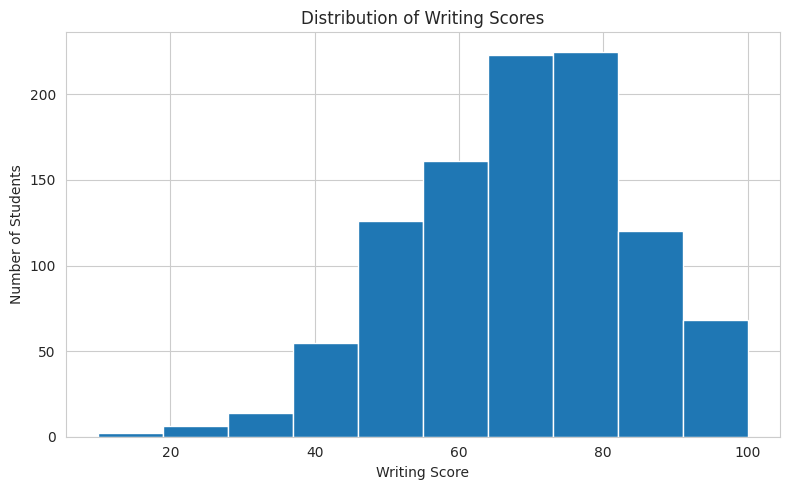

In [23]:
plt.figure(figsize=(8, 5))

plt.hist(df["writing score"], bins=10)

plt.title("Distribution of Writing Scores")
plt.xlabel("Writing Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()